# Prueba técnica: demanda transaccional por terminal y operación

Autor: Juan Esteban Cardozo

Tengo cuatro meses de transacciones (31 de enero a 31 de mayo de 2017) de varias terminales y operaciones. Quiero entender cómo se comporta el volumen y pronosticar la demanda diaria por operación en cada terminal para los 15 días siguientes (1 al 15 de junio de 2017). El orden del cuaderno es: calidad de datos, exploración, selección de 5 terminales y 5 operaciones, modelado con validación temporal, pronóstico final y conclusiones.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3, 'axes.titlesize': 11})
AZUL, NARANJA, GRIS = '#1f5f8b', '#d9822b', '#8a8a8a'

## Carga de datos

La ruta es relativa a la carpeta del cuaderno. Si el archivo no está (por ejemplo en Colab), pide subirlo.

In [2]:
ruta = None
for r in ['../data/data_01.txt', 'data/data_01.txt', 'data_01.txt']:
    if Path(r).exists():
        ruta = r
        break
if ruta is None:
    try:
        from google.colab import files
        ruta = list(files.upload())[0]   # subir data_01.txt
    except ImportError:
        raise FileNotFoundError('No encuentro data_01.txt, ponlo en la carpeta data/')

# carpeta de salidas junto a data/ (o en la carpeta actual si estoy en Colab)
OUT = Path(ruta).resolve().parent.parent / 'outputs' if Path(ruta).parent.name == 'data' else Path('outputs')
OUT.mkdir(exist_ok=True)

df = pd.read_csv(ruta, sep='\t', parse_dates=['fecha'])
df['dia'] = df['fecha'].dt.normalize()
df['hora'] = df['fecha'].dt.hour
print(df.shape)
df.head()

(775466, 5)


,fecha,idTerminal,oper,dia,hora
0,2017-01-31 08:19:33,1828,0,2017-01-31,8
1,2017-01-31 08:47:16,1828,1,2017-01-31,8
2,2017-01-31 08:48:07,1828,1,2017-01-31,8
3,2017-01-31 08:48:58,1828,1,2017-01-31,8
4,2017-01-31 08:49:53,1828,1,2017-01-31,8


## A. Calidad de los datos

Reviso tipos, nulos, duplicados, rango de fechas, días sin datos, horarios y comportamiento por terminal y operación.

In [3]:
print(df[['fecha', 'idTerminal', 'oper']].dtypes, '\n')
print('nulos:', int(df[['fecha', 'idTerminal', 'oper']].isna().sum().sum()))
print('filas duplicadas exactas:', int(df.duplicated(['fecha', 'idTerminal', 'oper']).sum()))
print('rango:', df.fecha.min(), '->', df.fecha.max())
print('terminales:', df.idTerminal.nunique(), '| operaciones:', df.oper.nunique())
print('milisegundos distintos de cero:', int((df.fecha.dt.microsecond > 0).sum()))

todos = pd.date_range(df.dia.min(), df.dia.max())
diario = df.groupby('dia').size().reindex(todos, fill_value=0)
print('días del calendario:', len(todos), '| días sin ninguna transacción:', int((diario == 0).sum()))

fecha         datetime64[us]
idTerminal             int64
oper                   int64
dtype: object 

nulos: 0


filas duplicadas exactas: 0
rango: 2017-01-31 08:19:33 -> 2017-05-31 23:59:48
terminales: 47 | operaciones: 46


milisegundos distintos de cero: 0
días del calendario: 121 | días sin ninguna transacción: 0


No hay nulos ni duplicados exactos y todos los días del calendario tienen transacciones. Falta ver si hay terminales que dejan de reportar o empiezan tarde, que es lo que pasa cuando una se apaga o se instala.

In [4]:
term = df.groupby('idTerminal').agg(n=('oper', 'size'), primer_dia=('dia', 'min'), ultimo_dia=('dia', 'max'),
                                    dias_con_datos=('dia', 'nunique'))
term['dias_sin_datos'] = len(todos) - term.dias_con_datos
raras = term[(term.primer_dia > '2017-02-01') | (term.ultimo_dia < '2017-05-31') | (term.dias_sin_datos > 3)]
print('terminales con historia incompleta o varios días sin datos:')
print(raras.to_string())
print('\nterminales con los', len(todos), 'días completos:', int((term.dias_con_datos == len(todos)).sum()), 'de', len(term))

terminales con historia incompleta o varios días sin datos:
                n primer_dia ultimo_dia  dias_con_datos  dias_sin_datos
idTerminal                                                             
1515         4325 2017-04-06 2017-05-31              46              75
1597         9188 2017-01-31 2017-05-31             104              17
1828        19576 2017-01-31 2017-05-19             109              12
1896        21403 2017-01-31 2017-05-31             116               5
1963        16429 2017-01-31 2017-04-07              67              54
1986         8183 2017-01-31 2017-05-31             117               4
1994        15108 2017-01-31 2017-05-31             116               5

terminales con los 121 días completos: 26 de 47


Solo 26 de las 47 terminales tienen los 121 días completos. En el resto casi siempre faltan entre 1 y 4 días, pero hay casos que sí llaman la atención: la 1963 deja de reportar después del 7 de abril (67 días con datos), la 1828 después del 19 de mayo (109 días) y la 1515 aparece apenas el 6 de abril (46 días). La 1597 tiene 17 días sin datos, y la 1896 y la 1994 cinco cada una. No sé si fueron apagones, cierres o cambios de red. Para el modelo basta con saber que en esas terminales un cero no es falta de demanda, así que no las uso como candidatas.

In [5]:
# primer y ultimo dia: ¿vienen completos?
horas = df.groupby(['dia', 'hora']).size().unstack(fill_value=0)
martes_tipicos = horas[(horas.index.dayofweek == 1) & (horas.index > '2017-01-31') & (horas.index < '2017-05-31')].mean()
comp = pd.DataFrame({'31 ene (martes)': horas.loc['2017-01-31'], 'martes típico': martes_tipicos.round(0),
                     '31 may (miércoles)': horas.loc['2017-05-31']})
print(comp.T.to_string())
print('\nprimera fila:', df.fecha.min(), '| última fila:', df.fecha.max())

hora                  0    1     2     3    4     5      6      7      8      9      10     11     12     13     14     15     16     17      18     19     20     21     22    23
31 ene (martes)      0.0  0.0   0.0   0.0  0.0   0.0    0.0    0.0   16.0   87.0  220.0  244.0  447.0  535.0  537.0  581.0  638.0  769.0   806.0  519.0  321.0  197.0   78.0  33.0
martes típico       11.0  6.0   5.0   3.0  7.0  35.0  150.0  264.0  405.0  560.0  585.0  552.0  612.0  629.0  613.0  585.0  532.0  628.0   559.0  311.0  177.0   94.0   52.0  22.0
31 may (miércoles)  36.0  5.0  15.0  12.0  7.0  95.0  345.0  469.0  648.0  947.0  896.0  880.0  914.0  983.0  935.0  961.0  913.0  996.0  1018.0  736.0  437.0  225.0  132.0  47.0

primera fila: 2017-01-31 08:19:33 | última fila: 2017-05-31 23:59:48


El 31 de enero es un día parcial: la primera transacción es a las 8:19 y a las 9 de la mañana lleva 87, contra unas 560 de un martes normal. Su total (6.028) queda bajo para un martes. Lo dejo porque es un solo día de 121 y el modelo lo verá como un martes algo bajo. El 31 de mayo sí está completo, con transacciones hasta las 23:59:48, así que el pronóstico puede arrancar el 1 de junio sin ajustes.

In [6]:
# operaciones con pocos datos
ops = df.groupby('oper').size().sort_values(ascending=False)
print('operaciones con menos de 500 transacciones en 4 meses:', int((ops < 500).sum()), 'de', len(ops))
print('esas operaciones suman', round(ops[ops < 500].sum() / ops.sum() * 100, 2), '% del volumen')
print('operación 0 concentra', round(ops.iloc[0] / ops.sum() * 100, 1), '% del volumen')
print('top 5 operaciones:', round(ops.head(5).sum() / ops.sum() * 100, 1), '%')

operaciones con menos de 500 transacciones en 4 meses: 29 de 46
esas operaciones suman 0.32 % del volumen
operación 0 concentra 54.7 % del volumen
top 5 operaciones: 92.5 %


Hay una cola larga de operaciones casi sin uso y una operación dominante, la 0. Modelar esa cola con series diarias no tiene sentido: la mayoría de los días serían ceros.

### Festivos

Asumo el calendario de festivos de Colombia en 2017, que no viene en los datos: 9 de enero, 20 de marzo, 13 y 14 de abril (Jueves y Viernes Santo), 1 de mayo, 29 de mayo (Ascensión), 19 y 26 de junio. Entre el 1 y el 15 de junio no cae ninguno.

In [7]:
FEST = pd.to_datetime(['2017-01-09', '2017-03-20', '2017-04-13', '2017-04-14', '2017-05-01',
                       '2017-05-29', '2017-06-19', '2017-06-26'])
ref = diario.groupby(diario.index.dayofweek).median()
t = pd.DataFrame({'total': diario[diario.index.isin(FEST)]})
t['mediana mismo día de semana'] = [ref[d.dayofweek] for d in t.index]
t['razón'] = (t.total / t['mediana mismo día de semana']).round(2)
t

,total,mediana mismo día de semana,razón
2017-03-20,2200,6316.0,0.35
2017-04-13,2524,6529.0,0.39
2017-04-14,1472,7384.0,0.20
2017-05-01,3487,6316.0,0.55
2017-05-29,1986,6316.0,0.31


Los festivos quedan muy por debajo de lo normal para su día de la semana, entre 0,20 y 0,55 veces la mediana. El Viernes Santo (14 de abril) es el día más bajo de toda la base, con 1.472 transacciones, y el 29 de mayo (Ascensión) también es muy bajo. Los uso como variable, aunque en el entrenamiento solo hay cinco y por eso el efecto queda estimado con poca información.

## B. Análisis exploratorio

### Serie diaria total

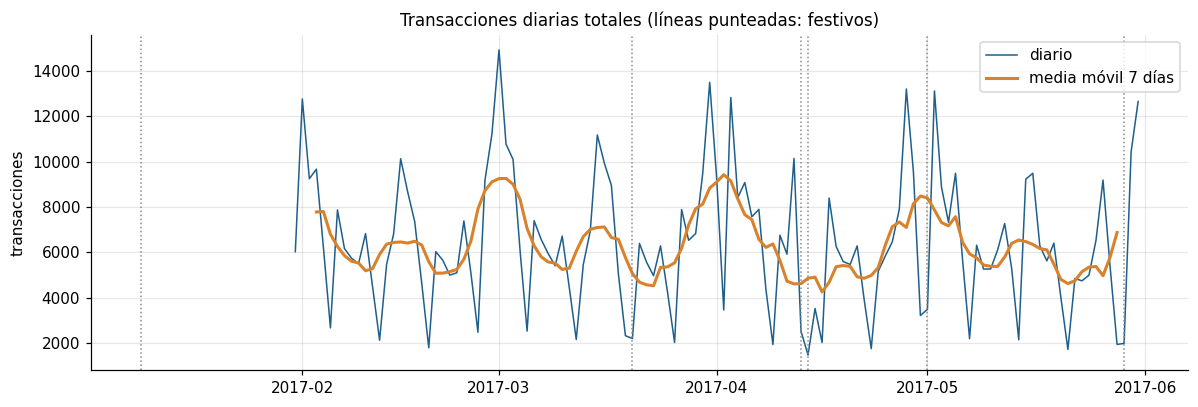

2017-01-01      6028
2017-02-01    181255
2017-03-01    208765
2017-04-01    186140
2017-05-01    193278
Freq: MS

media diaria por mes (meses completos):
2017-02-01    6473.0
2017-03-01    6734.0
2017-04-01    6205.0
2017-05-01    6235.0
Freq: MS


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(diario.index, diario.values, color=AZUL, lw=1, label='diario')
ax.plot(diario.index, diario.rolling(7, center=True).mean(), color=NARANJA, lw=2, label='media móvil 7 días')
for f in FEST[FEST <= todos[-1]]:
    ax.axvline(f, color=GRIS, ls=':', lw=1)
ax.set_title('Transacciones diarias totales (líneas punteadas: festivos)')
ax.legend(); ax.set_ylabel('transacciones')
fig.tight_layout(); fig.savefig(OUT / 'fig01_serie_diaria.png'); plt.show()
print(diario.resample('MS').sum().rename('total por mes').to_string())
print('\nmedia diaria por mes (meses completos):')
print(diario['2017-02-01':].resample('MS').mean().round(0).to_string())

La serie tiene un patrón semanal claro: picos entre semana y caídas los domingos. El promedio diario de los meses completos es parecido de un mes a otro (entre 6.200 y 6.700 transacciones), así que en estos cuatro meses no se ve tendencia. Las caídas más fuertes coinciden con festivos. Los días más altos (1 de marzo, 31 de marzo, 28 de abril y 2 de mayo) están pegados al cambio de mes, y eso lo reviso más abajo.

### Día de la semana y hora del día

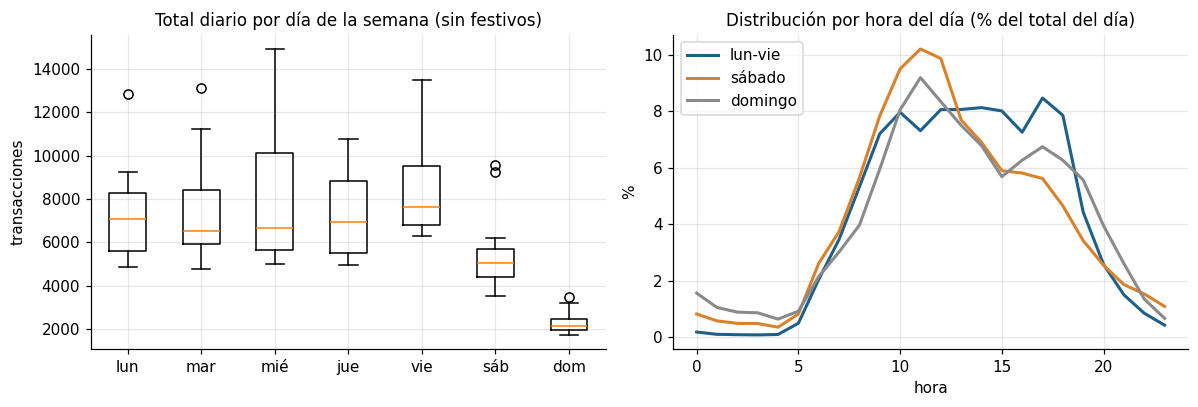

promedio diario / promedio de lun-vie:
lun    0.95
mar    0.96
mié    1.06
jue    0.93
vie    1.10
sáb    0.69
dom    0.29

transacciones entre 0 y 5 h: 1.6 %
transacciones entre 8 y 18 h: 82.6 %
hora pico lun-vie: 17 | hora pico sábado: 11 | hora pico domingo: 11


In [9]:
nombres = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']
d_ok = diario[(diario.index > '2017-01-31') & (~diario.index.isin(FEST))]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].boxplot([d_ok[d_ok.index.dayofweek == k] for k in range(7)], labels=nombres)
axs[0].set_title('Total diario por día de la semana (sin festivos)')
axs[0].set_ylabel('transacciones')

d_h = df[(df.dia > '2017-01-31') & (~df.dia.isin(FEST))].copy()
d_h['tipo'] = np.where(d_h.dia.dt.dayofweek < 5, 'lun-vie', np.where(d_h.dia.dt.dayofweek == 5, 'sábado', 'domingo'))
h = d_h.groupby(['tipo', 'hora']).size().unstack(0)
h = h / h.sum()
for c, col in zip(['lun-vie', 'sábado', 'domingo'], [AZUL, NARANJA, GRIS]):
    axs[1].plot(h.index, h[c] * 100, label=c, color=col, lw=2)
axs[1].set_title('Distribución por hora del día (% del total del día)')
axs[1].set_xlabel('hora'); axs[1].set_ylabel('%'); axs[1].legend()
fig.tight_layout(); fig.savefig(OUT / 'fig02_dia_semana_hora.png'); plt.show()

med = d_ok.groupby(d_ok.index.dayofweek).mean()
print('promedio diario / promedio de lun-vie:')
print((med / med[:5].mean()).round(2).rename(index=dict(enumerate(nombres))).to_string())
print('\ntransacciones entre 0 y 5 h:', round(df[df.hora < 6].shape[0] / len(df) * 100, 1), '%')
print('transacciones entre 8 y 18 h:', round(df[df.hora.between(8, 18)].shape[0] / len(df) * 100, 1), '%')
print('hora pico lun-vie:', h['lun-vie'].idxmax(), '| hora pico sábado:', h['sábado'].idxmax(), '| hora pico domingo:', h['domingo'].idxmax())

Miércoles y viernes son los días más altos; el sábado baja a cerca de 70% de un día hábil promedio y el domingo a cerca de 30%. Por hora, el 83% de las transacciones ocurre entre las 8 y las 18, y de la medianoche a las 5 de la mañana solo hay 1,6%. Entre semana el pico es en la tarde (hora 17); sábados y domingos, en la mañana (hora 11). La tabla impresa compara cada día con el promedio de lunes a viernes.

### Día del mes

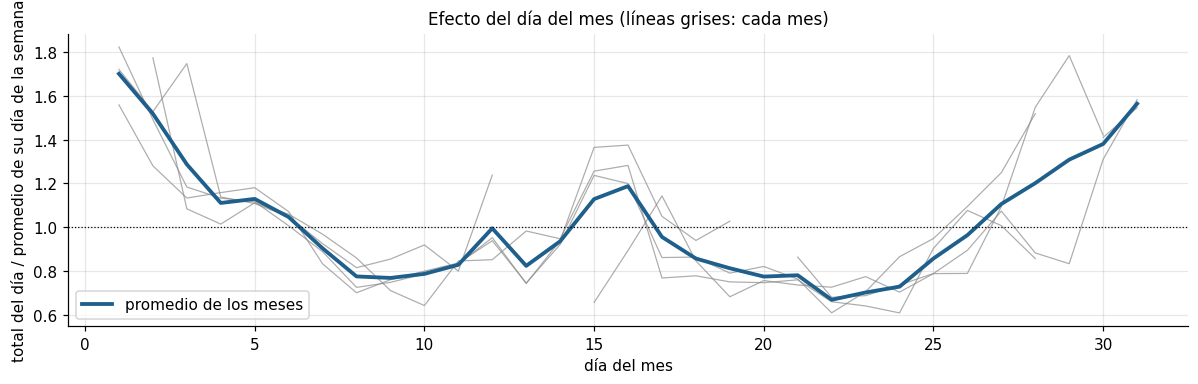

razón promedio día 1: 1.7 | día 2: 1.52 | día 22: 0.67 | día 31: 1.56
razón promedio días 8-11: 0.85 | días 15-16: 1.07 | días 1-3: 1.31
días 1 a 15 de junio, razón esperada media: 1.02 | promedio general: 1.02


In [10]:
# razón entre el total del día y el promedio de su día de la semana (sin festivos ni el 31 de enero)
d_m = diario[(diario.index > '2017-01-31') & (~diario.index.isin(FEST))]
razon = d_m / d_m.groupby(d_m.index.dayofweek).transform('mean')
tab = pd.DataFrame({'razon': razon, 'dia': razon.index.day, 'mes': razon.index.month}).pivot_table(index='dia', columns='mes', values='razon')
fig, ax = plt.subplots(figsize=(11, 3.6))
for c in tab.columns:
    ax.plot(tab.index, tab[c], color=GRIS, lw=.8, alpha=.7)
ax.plot(tab.index, tab.mean(axis=1), color=AZUL, lw=2.5, label='promedio de los meses')
ax.axhline(1, color='black', lw=.8, ls=':')
ax.set_xlabel('día del mes'); ax.set_ylabel('total del día / promedio de su día de la semana')
ax.set_title('Efecto del día del mes (líneas grises: cada mes)'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'fig02b_dia_del_mes.png'); plt.show()
prom_dm = tab.mean(axis=1)
print('razón promedio día 1:', round(prom_dm[1], 2), '| día 2:', round(prom_dm[2], 2), '| día 22:', round(prom_dm[22], 2), '| día 31:', round(prom_dm[31], 2))
print('razón promedio días 8-11:', round(prom_dm[8:12].mean(), 2), '| días 15-16:', round(prom_dm[15:17].mean(), 2), '| días 1-3:', round(prom_dm[1:4].mean(), 2))
print('días 1 a 15 de junio, razón esperada media:', round(prom_dm[1:16].mean(), 2), '| promedio general:', round(prom_dm.mean(), 2))

Es lo que más me llamó la atención del análisis. Quitado el efecto del día de la semana, el volumen sube con fuerza al cambiar de mes: el día 1 vale en promedio 1,7 veces lo normal, el día 31 vale 1,56, y a mitad de mes (días 8 a 11 y del 20 al 24) queda entre 0,7 y 0,85. También hay un repunte pequeño hacia la quincena (días 15 y 16). El patrón se repite en los cuatro meses (líneas grises), pero con cuatro ciclos no puedo asegurar que siga igual. Puede deberse a los ciclos de pago de la gente, aunque eso es una suposición mía, los datos no lo muestran. Para el pronóstico pesa bastante, porque el 1 y 2 de junio caen en la parte alta del ciclo y un modelo que solo mire el día de la semana los subestimaría.

### Terminales y operaciones principales

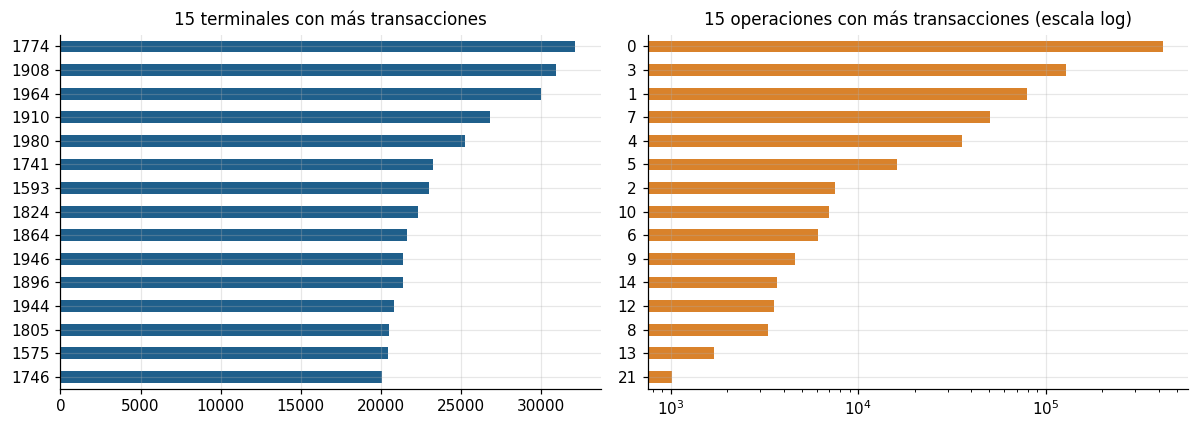

terminal líder: 1774 32122 | terminal con menos: 1515 4325
mediana por terminal: 16494
oper
0    423929
3    127399
1     79195
7     50662
4     35817


In [11]:
tt = df.groupby('idTerminal').size().sort_values(ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
tt.head(15)[::-1].plot.barh(ax=axs[0], color=AZUL)
axs[0].set_title('15 terminales con más transacciones'); axs[0].set_ylabel('')
ops.head(15)[::-1].plot.barh(ax=axs[1], color=NARANJA)
axs[1].set_xscale('log'); axs[1].set_title('15 operaciones con más transacciones (escala log)'); axs[1].set_ylabel('')
fig.tight_layout(); fig.savefig(OUT / 'fig03_top_terminales_ops.png'); plt.show()
print('terminal líder:', tt.index[0], tt.iloc[0], '| terminal con menos:', tt.index[-1], tt.iloc[-1])
print('mediana por terminal:', int(tt.median()))
print(ops.head(5).to_string())

El volumen por terminal es desigual en los extremos: la líder (1774) tiene 32.122 transacciones y la menor (1515, que además empezó en abril) 4.325, con una mediana de 16.494. En operaciones uso escala logarítmica porque la 0 tiene más de 420.000 transacciones y la 3 cerca de 127.000, mientras que de la décima en adelante hay pocos miles.

### Concentración

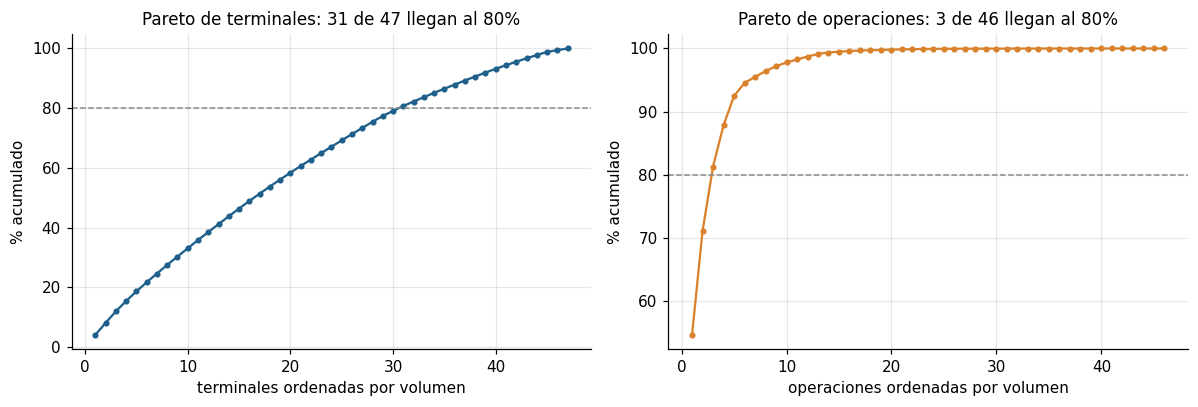

top 10 terminales: 33.1 % | top 3 operaciones: 81.3 %
top 4 operaciones: 87.8 %


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
k80s = {}
for ax, s, nom, col in [(axs[0], tt, 'terminales', AZUL), (axs[1], ops, 'operaciones', NARANJA)]:
    cum = s.cumsum() / s.sum() * 100
    ax.plot(range(1, len(s) + 1), cum.values, color=col, marker='o', ms=3)
    ax.axhline(80, color=GRIS, ls='--', lw=1)
    k80 = int((cum < 80).sum() + 1); k80s[nom] = k80
    ax.set_title(f'Pareto de {nom}: {k80} de {len(s)} llegan al 80%')
    ax.set_xlabel(f'{nom} ordenadas por volumen'); ax.set_ylabel('% acumulado')
fig.tight_layout(); fig.savefig(OUT / 'fig04_pareto.png'); plt.show()
print('top 10 terminales:', round(tt.head(10).sum() / tt.sum() * 100, 1), '% | top 3 operaciones:', round(ops.head(3).sum() / ops.sum() * 100, 1), '%')
print('top 4 operaciones:', round(ops.head(4).sum() / ops.sum() * 100, 1), '%')

La concentración es muy distinta entre terminales y operaciones. En operaciones, tres de las 46 suman 81% de las transacciones y cinco suman 92,5%. En terminales hacen falta casi dos tercios (31 de 47) para llegar al 80%, y las diez mayores suman solo 33%. La carga está repartida entre muchas terminales, algo a tener en cuenta si se planea capacidad terminal por terminal y no solo en agregado.

### Mapa de calor terminal por operación

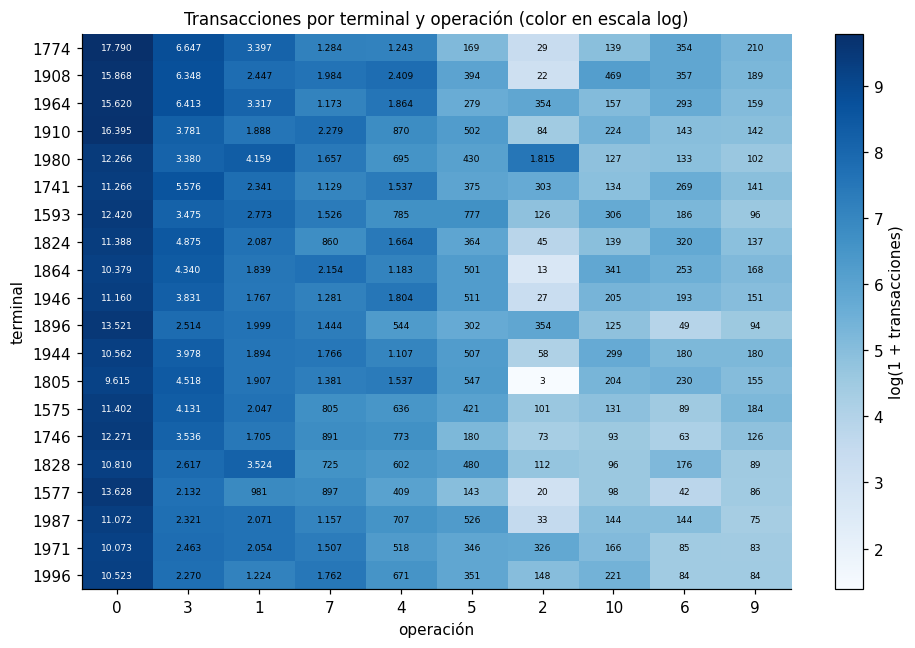

peso de la operación 0 por terminal (top 20): min 0.48 max 0.74
peso de la operación 3 por terminal (top 20): min 0.12 max 0.24


In [13]:
top_t = tt.head(20).index
top_o = ops.head(10).index
m = df[df.idTerminal.isin(top_t) & df.oper.isin(top_o)].groupby(['idTerminal', 'oper']).size().unstack(fill_value=0)
m = m.loc[top_t, top_o]
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(np.log1p(m.values), cmap='Blues', aspect='auto')
ax.set_xticks(range(len(top_o))); ax.set_xticklabels(top_o)
ax.set_yticks(range(len(top_t))); ax.set_yticklabels(top_t)
ax.grid(False); ax.set_xlabel('operación'); ax.set_ylabel('terminal')
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.text(j, i, f'{m.values[i, j]:,}'.replace(',', '.'), ha='center', va='center', fontsize=6,
                color='white' if np.log1p(m.values[i, j]) > 8 else 'black')
ax.set_title('Transacciones por terminal y operación (color en escala log)')
fig.colorbar(im, ax=ax, label='log(1 + transacciones)')
fig.tight_layout(); fig.savefig(OUT / 'fig05_mapa_calor.png'); plt.show()
# peso de la operacion 0 y de la 3 dentro de cada terminal grande
mix = m.div(m.sum(axis=1), axis=0)
print('peso de la operación 0 por terminal (top 20): min', round(mix[0].min(), 2), 'max', round(mix[0].max(), 2))
print('peso de la operación 3 por terminal (top 20): min', round(mix[3].min(), 2), 'max', round(mix[3].max(), 2))

La operación 0 domina en todas las terminales, pero con peso distinto: entre 48% y 74% del volumen en cada una de las 20 más grandes. La operación 3 pesa entre 12% y 24%. Como la mezcla cambia de una terminal a otra, un modelo agregado perdería esa información; por eso trato cada combinación terminal por operación como una serie aparte.

### Volatilidad y días en cero por serie

combinaciones terminal-operación observadas: 1296
con al menos 100 transacciones: 405


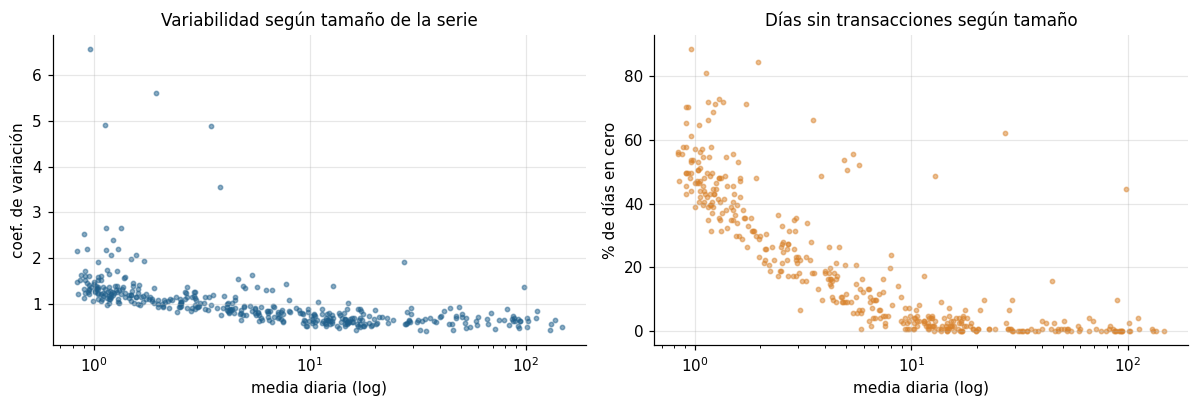

series con media diaria >= 10: 150 | mediana de cv: 0.64 | mediana de % de ceros: 0.8
series con media diaria < 1: 23 | mediana de cv: 1.44 | mediana de % de ceros: 54.0


In [14]:
idx = pd.date_range('2017-01-31', '2017-05-31')
panel = df.groupby(['idTerminal', 'oper', 'dia']).size().unstack('dia').reindex(columns=idx).fillna(0)
stats = pd.DataFrame({'media': panel.mean(axis=1), 'cv': panel.std(axis=1) / panel.mean(axis=1),
                      'pct_ceros': (panel == 0).mean(axis=1) * 100, 'total': panel.sum(axis=1)})
print('combinaciones terminal-operación observadas:', len(panel))
stats = stats[stats.total >= 100]
print('con al menos 100 transacciones:', len(stats))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].scatter(stats.media, stats.cv, s=8, alpha=.5, color=AZUL); axs[0].set_xscale('log')
axs[0].set_xlabel('media diaria (log)'); axs[0].set_ylabel('coef. de variación'); axs[0].set_title('Variabilidad según tamaño de la serie')
axs[1].scatter(stats.media, stats.pct_ceros, s=8, alpha=.5, color=NARANJA); axs[1].set_xscale('log')
axs[1].set_xlabel('media diaria (log)'); axs[1].set_ylabel('% de días en cero'); axs[1].set_title('Días sin transacciones según tamaño')
fig.tight_layout(); fig.savefig(OUT / 'fig06_volatilidad.png'); plt.show()
print('series con media diaria >= 10:', int((stats.media >= 10).sum()), '| mediana de cv:', round(stats[stats.media >= 10].cv.median(), 2),
      '| mediana de % de ceros:', round(stats[stats.media >= 10].pct_ceros.median(), 1))
print('series con media diaria < 1:', int((stats.media < 1).sum()), '| mediana de cv:', round(stats[stats.media < 1].cv.median(), 2),
      '| mediana de % de ceros:', round(stats[stats.media < 1].pct_ceros.median(), 0))

Las series grandes (media diaria de 10 o más) son bastante regulares: casi no tienen días en cero y su coeficiente de variación mediano es 0,64. Las pequeñas (menos de una transacción diaria) tienen más de la mitad de los días en cero y un coeficiente de variación mayor a 1,4. En esas series el pronóstico diario es poco confiable casi por definición, porque el ruido de un conteo bajo ya es grande. Esto pesó en la selección: preferí combinaciones con volumen y cobertura suficientes. De las 1.296 combinaciones terminal por operación que aparecen en la base, solo 405 llegan a 100 transacciones en cuatro meses.

## C. Selección de 5 operaciones y 5 terminales

Como la demanda se modela por combinación de terminal y operación, escogí operaciones y terminales de modo que las 25 combinaciones tuvieran buena historia. Criterios:

Operaciones: las 5 de mayor volumen, siempre que en la mediana de terminales haya actividad en al menos 85% de los días.

Terminales: con los 121 días de datos (descarté 1963, 1828, 1515 y las que tienen días sin datos) y actividad en al menos 95% de los días en cada una de las 5 operaciones, para que un cero sea demanda real y no una terminal apagada. Entre las que cumplen tomé cinco repartidas en la distribución de volumen (la mayor, la menor y tres intermedias), para ver si el modelo se comporta igual en terminales grandes y pequeñas.

In [15]:
cob_media = (panel > 0).mean(axis=1).groupby(level=1).median()
tabla_ops = pd.DataFrame({'transacciones': ops, 'cobertura_mediana': cob_media.reindex(ops.index).round(2)}).head(8)
print(tabla_ops.to_string())
OPS = [int(o) for o in tabla_ops.index if tabla_ops.loc[o, 'cobertura_mediana'] >= .85][:5]
print('\noperaciones elegidas:', OPS)

      transacciones  cobertura_mediana
oper                                  
0            423929               0.99
3            127399               0.99
1             79195               0.97
7             50662               0.95
4             35817               0.89
5             16124               0.74
2              7526               0.24
10             6988               0.51

operaciones elegidas: [0, 3, 1, 7, 4]


In [16]:
cand = term[term.dias_con_datos == len(todos)].index
cov_min = (panel.loc[panel.index.get_level_values(1).isin(OPS)] > 0).mean(axis=1).groupby(level=0).min()
vol = df[df.oper.isin(OPS)].groupby('idTerminal').size()
elegibles = [t for t in cand if cov_min.get(t, 0) >= .95]
vol_el = vol[elegibles].sort_values()
print('terminales elegibles:', len(elegibles), 'de', len(term))
pos = np.linspace(0, len(vol_el) - 1, 5).round().astype(int)
TERM = [int(vol_el.index[p]) for p in pos][::-1]
sel = pd.DataFrame({'transacciones_5ops': vol[TERM], 'cobertura_minima': cov_min[TERM].round(3)})
print('terminales elegidas:', TERM)
sel

terminales elegibles: 11 de 47
terminales elegidas: [1774, 1910, 1946, 1805, 1981]


,transacciones_5ops,cobertura_minima
idTerminal,,
1774,30361,0.959
1910,25213,0.959
1946,19843,0.950
1805,18958,0.975
1981,15065,0.967


In [17]:
cols = [(t, o) for t in TERM for o in OPS]
Y = panel.loc[cols].T            # filas: días, columnas: (terminal, operación)
resumen = pd.DataFrame({'media_diaria': Y.mean(), 'cv': Y.std() / Y.mean(), 'pct_ceros': (Y == 0).mean() * 100}).round(2)
resumen.index.names = ['terminal', 'oper']
print('media diaria'); print(resumen.media_diaria.unstack().to_string())
print('\n% de días en cero'); print(resumen.pct_ceros.unstack().to_string())
print('\ncoeficiente de variación'); print(resumen.cv.unstack().to_string())

media diaria
oper           0      3      1      7      4
terminal                                    
1774      147.02  54.93  28.07  10.61  10.27
1910      135.50  31.25  15.60  18.83   7.19
1946       92.23  31.66  14.60  10.59  14.91
1805       79.46  37.34  15.76  11.41  12.70
1981       60.08  28.82  11.88  14.83   8.90

% de días en cero
oper         0     3     1     7     4
terminal                              
1774      0.00  0.00  0.83  1.65  4.13
1910      0.00  0.00  3.31  2.48  4.13
1946      0.00  0.00  2.48  3.31  4.96
1805      0.00  0.00  1.65  2.48  1.65
1981      0.83  0.83  1.65  0.83  3.31

coeficiente de variación
oper         0     3     1     7     4
terminal                              
1774      0.49  0.48  0.57  0.51  0.66
1910      0.63  0.61  0.68  0.58  0.71
1946      0.67  0.64  0.66  0.61  0.88
1805      0.65  0.62  0.60  0.57  0.75
1981      0.71  0.65  0.65  0.56  0.86


Quedaron las operaciones 0, 3, 1, 7 y 4, que concentran 92,5% del volumen. La 5 se quedó fuera porque en la mediana de terminales solo tiene actividad el 74% de los días. Solo 11 de las 47 terminales cumplen los criterios de cobertura, y de ahí salen la 1774 (la de mayor volumen), la 1910, la 1946, la 1805 y la 1981 (la de menor volumen entre las elegibles). Cubrí terminales grandes y medianas, pero no pequeñas, y eso es una limitación de la selección. Las 25 combinaciones tienen entre 0% y 5% de días en cero, con medias diarias de unas 6 a 147 transacciones; por eso me pareció razonable rellenar con cero los días sin transacciones: las terminales estaban activas y el cero es demanda observada, no un dato faltante. Las combinaciones con la operación 4 son las más ralas y espero que sean las más difíciles.

## D. Modelado

### Planteamiento

Pronostico 15 días hacia adelante para cada una de las 25 series. La historia es corta (121 días, unas 17 semanas), así que cuido la validación. Uso origen móvil: cuatro cortes, cada uno 15 días después del anterior, y en cada uno se pronostican los 15 días siguientes sin haberlos visto. El último corte, del 17 al 31 de mayo, es el conjunto de prueba; los otros tres muestran qué tan estable es el resultado. El primer corte entrena con solo 61 días.

Modelos comparados:

1. Ingenuo: repite el último valor observado.
2. Ingenuo estacional: repite la última semana.
3. Media móvil de 7 días, constante.
4. Promedio por día de la semana: media de las últimas cuatro semanas para el mismo día.
5. Holt-Winters con estacionalidad semanal aditiva, uno por serie.
6. Regresión de Poisson por serie con día de la semana y festivo.
7. Regresión de Poisson por serie con lo anterior más el efecto de inicio y fin de mes y la quincena (lo que vi en la gráfica del día del mes).
8. Gradient boosting global (un solo modelo para las 25 series) con pérdida de Poisson y variables: día de la semana, festivo, día del mes, cercanía al borde de mes, horizonte, rezagos y promedios recientes, nivel de la serie y códigos de terminal y operación.
9. Mezcla: promedio de los modelos 7 y 8.

Uso Poisson porque la variable es un conteo no negativo y varias series son pequeñas. Métricas: MAE y RMSE en transacciones, WAPE (suma de errores absolutos sobre suma de valores reales; lo prefiero al MAPE porque con conteos pequeños el MAPE se dispara), sMAPE y sesgo (error con signo sobre el total real; positivo es sobreestimar).

In [18]:
H = 15
FESTSET = set(FEST)
def es_fest(d): return int(pd.Timestamp(d) in FESTSET)

def variables(y, fechas, i, h):
    # variables para predecir el día i+h conociendo solo y[:i]
    j = i + h
    k = h // 7 + 1                      # semanas hacia atrás para tener el mismo día ya observado
    base = j - 7 * k
    lags = [y[base - 7 * m] for m in range(4) if base - 7 * m >= 0]
    conocido = y[:i]
    f = fechas[j]
    return [f.dayofweek, es_fest(f), h, y[base], np.mean(lags), conocido[-7:].mean(),
            conocido[-28:].mean(), conocido[-1], np.log1p(conocido[-28:].mean()), f.day, borde_mes(f)]

def borde_mes(d):
    # días que faltan al borde de mes más cercano (0 el día 1 y el último día)
    return min(d.day - 1, d.days_in_month - d.day)

def dummies(fechas, calendario=False):
    X = np.column_stack([np.eye(7)[[d.dayofweek for d in fechas]], [es_fest(d) for d in fechas]])
    if calendario:   # efecto de inicio/fin de mes (decae con la distancia) y quincena
        extra = np.column_stack([[np.exp(-borde_mes(d) / 4) for d in fechas], [int(d.day in (15, 16)) for d in fechas]])
        X = np.column_stack([X, extra])
    return X

def pronosticar(ys, fechas, o):
    # predice los días o..o+14 con los datos anteriores a o; ys: matriz (días, series)
    m = ys.shape[1]
    sal = {}
    sal['ingenuo'] = np.tile(ys[o - 1], (H, 1))
    sal['ing_estacional'] = np.array([ys[o - 7 + (h % 7)] for h in range(H)])
    sal['prom_dia_sem'] = np.array([np.mean([ys[o - 7 + (h % 7) - 7 * q] for q in range(4)], axis=0) for h in range(H)])
    sal['media_movil7'] = np.tile(ys[o - 7:o].mean(0), (H, 1))
    hw = np.zeros((H, m)); glm = np.zeros((H, m)); glc = np.zeros((H, m))
    for s in range(m):
        try:
            hw[:, s] = ExponentialSmoothing(ys[:o, s] + 0.0, seasonal='add', seasonal_periods=7).fit().forecast(H)
        except Exception:
            hw[:, s] = ys[o - 7:o, s].mean()
        g = PoissonRegressor(alpha=1e-6, max_iter=500).fit(dummies(fechas[:o]), ys[:o, s])
        glm[:, s] = g.predict(dummies(fechas[o:o + H]))
        g2 = PoissonRegressor(alpha=1e-6, max_iter=500).fit(dummies(fechas[:o], True), ys[:o, s])
        glc[:, s] = g2.predict(dummies(fechas[o:o + H], True))
    sal['holt_winters'] = np.clip(hw, 0, None)
    sal['poisson_dia_sem'] = glm
    sal['poisson_calendario'] = glc
    # boosting global: muestras (origen i, horizonte h) cuyo objetivo se conoce antes de o
    X, t = [], []
    for s in range(m):
        for i in range(28, o):
            for h in range(H):
                if i + h <= o - 1:
                    X.append(variables(ys[:, s], fechas, i, h) + [s // 5, s % 5]); t.append(ys[i + h, s])
    mod = HistGradientBoostingRegressor(loss='poisson', max_iter=200, learning_rate=.05, max_depth=4,
                                        min_samples_leaf=20, categorical_features=[0, 11, 12], random_state=0)
    mod.fit(np.array(X), np.array(t))
    gb = np.zeros((H, m))
    for s in range(m):
        gb[:, s] = mod.predict(np.array([variables(ys[:, s], fechas, o, h) + [s // 5, s % 5] for h in range(H)]))
    sal['boosting_global'] = gb
    sal['mezcla'] = (glc + gb) / 2
    return sal

def metricas(real, pred):
    e = pred - real
    den = np.abs(real) + np.abs(pred)
    smape = np.where(den == 0, 0, 2 * np.abs(e) / np.where(den == 0, 1, den)).mean()
    return dict(MAE=np.abs(e).mean(), RMSE=np.sqrt((e ** 2).mean()), WAPE=np.abs(e).sum() / real.sum(),
                sMAPE=smape, sesgo=e.sum() / real.sum())

In [19]:
fechas = pd.date_range('2017-01-31', '2017-06-15')   # incluye los 15 días a pronosticar
ys = Y.values.astype(float)
n = len(ys)
ORIGENES = [n - 60, n - 45, n - 30, n - 15]          # el último es el conjunto de prueba

pred_folds, filas = {}, []
for o in ORIGENES:
    pr = pronosticar(ys, fechas, o)
    pred_folds[o] = pr
    for nom, p in pr.items():
        filas.append(dict(modelo=nom, corte=str(fechas[o].date()), **metricas(ys[o:o + H], p)))
res = pd.DataFrame(filas)
orden = ['ingenuo', 'ing_estacional', 'media_movil7', 'prom_dia_sem', 'holt_winters',
         'poisson_dia_sem', 'poisson_calendario', 'boosting_global', 'mezcla']
print('WAPE por corte (el nombre de la columna es el primer día pronosticado):')
print(res.pivot(index='modelo', columns='corte', values='WAPE').loc[orden].round(3).to_string())

WAPE por corte (el nombre de la columna es el primer día pronosticado):
corte               2017-04-02  2017-04-17  2017-05-02  2017-05-17
modelo                                                            
ingenuo                  0.954       0.693       0.771       0.686
ing_estacional           0.720       0.644       0.775       0.588
media_movil7             0.671       0.507       0.578       0.525
prom_dia_sem             0.474       0.495       0.397       0.445
holt_winters             0.823       0.469       0.604       0.513
poisson_dia_sem          0.387       0.435       0.394       0.432
poisson_calendario       0.383       0.368       0.320       0.339
boosting_global          0.371       0.428       0.387       0.350
mezcla                   0.364       0.384       0.330       0.322


In [20]:
prom = res.groupby('modelo')[['MAE', 'RMSE', 'WAPE', 'sMAPE', 'sesgo']].mean().loc[orden].round(3)
prueba = res[res.corte == str(fechas[ORIGENES[-1]].date())].set_index('modelo')[['MAE', 'RMSE', 'WAPE', 'sMAPE', 'sesgo']].loc[orden].round(3)
print('Promedio de los 4 cortes:'); print(prom.to_string())
print('\nConjunto de prueba (17 al 31 de mayo):'); print(prueba.to_string())

Promedio de los 4 cortes:
                       MAE    RMSE   WAPE  sMAPE  sesgo
modelo                                                 
ingenuo             27.770  48.962  0.776  0.871 -0.038
ing_estacional      24.387  46.213  0.682  0.725  0.071
media_movil7        20.403  37.194  0.570  0.607  0.096
prom_dia_sem        16.246  30.479  0.453  0.523  0.014
holt_winters        21.522  39.980  0.602  0.623  0.107
poisson_dia_sem     14.770  27.414  0.412  0.492 -0.017
poisson_calendario  12.648  23.770  0.353  0.456 -0.053
boosting_global     13.773  25.507  0.384  0.474  0.031
mezcla              12.544  23.506  0.350  0.449 -0.011

Conjunto de prueba (17 al 31 de mayo):
                       MAE    RMSE   WAPE  sMAPE  sesgo
modelo                                                 
ingenuo             24.808  42.375  0.686  0.660  0.378
ing_estacional      21.272  41.880  0.588  0.668 -0.154
media_movil7        18.982  36.929  0.525  0.579 -0.131
prom_dia_sem        16.069  31.260  0.

In [21]:
MEJOR = prom.WAPE.idxmin()
BASES = ['ingenuo', 'ing_estacional', 'media_movil7', 'prom_dia_sem']
MEJOR_BASE = prom.loc[BASES].WAPE.idxmin()
print('mejor modelo por WAPE promedio:', MEJOR, '| mejor baseline:', MEJOR_BASE)
print('mejora del WAPE sobre el mejor baseline (promedio 4 cortes):',
      round((1 - prom.WAPE[MEJOR] / prom.WAPE[MEJOR_BASE]) * 100, 1), '%')
print('mejora en prueba:', round((1 - prueba.WAPE[MEJOR] / prueba.WAPE[MEJOR_BASE]) * 100, 1), '%')

# error según el horizonte (promedio de los 4 cortes)
hor = []
for o in ORIGENES:
    real = ys[o:o + H]; p = pred_folds[o][MEJOR]
    for lo_, hi_ in [(0, 5), (5, 10), (10, 15)]:
        hor.append(dict(tramo=f'días {lo_ + 1}-{hi_}', WAPE=np.abs(p[lo_:hi_] - real[lo_:hi_]).sum() / real[lo_:hi_].sum()))
print('\nWAPE por tramo del horizonte, modelo elegido:')
print(pd.DataFrame(hor).groupby('tramo').WAPE.mean().round(3).to_string())

mejor modelo por WAPE promedio: mezcla | mejor baseline: prom_dia_sem
mejora del WAPE sobre el mejor baseline (promedio 4 cortes): 22.7 %
mejora en prueba: 27.6 %

WAPE por tramo del horizonte, modelo elegido:
tramo
días 1-5      0.294
días 11-15    0.440
días 6-10     0.335


In [22]:
o = ORIGENES[-1]
real = ys[o:o + H]
por_serie = pd.DataFrame({
    'media_real': real.mean(0),
    'WAPE_modelo': np.abs(pred_folds[o][MEJOR] - real).sum(0) / real.sum(0),
    'WAPE_baseline': np.abs(pred_folds[o][MEJOR_BASE] - real).sum(0) / real.sum(0),
    'sesgo_modelo': (pred_folds[o][MEJOR] - real).sum(0) / real.sum(0)}, index=Y.columns).round(2)
por_serie.index.names = ['terminal', 'oper']
print(por_serie.to_string())
print('\nseries donde el modelo supera al baseline:', int((por_serie.WAPE_modelo < por_serie.WAPE_baseline).sum()), 'de 25')
print('WAPE de la suma de las 25 series (demanda total diaria):',
      round(np.abs(pred_folds[o][MEJOR].sum(1) - real.sum(1)).sum() / real.sum(), 3))
print('\nWAPE del modelo por operación en prueba:')
print(por_serie.groupby(level=1).apply(lambda g: (g.WAPE_modelo * g.media_real).sum() / g.media_real.sum()).round(2).to_string())

               media_real  WAPE_modelo  WAPE_baseline  sesgo_modelo
terminal oper                                                      
1774     0         148.07         0.22           0.34         -0.07
         3          52.73         0.26           0.33          0.03
         1          18.93         0.54           0.62          0.45
         7          12.40         0.33           0.43         -0.14
         4           6.07         0.80           0.80          0.75
1910     0         140.87         0.23           0.31         -0.06
         3          33.40         0.24           0.38         -0.06
         1          15.93         0.30           0.34          0.01
         7          19.80         0.22           0.23         -0.11
         4           6.67         0.42           0.52          0.14
1946     0          88.67         0.34           0.54         -0.03
         3          23.47         0.44           0.56          0.33
         1          12.40         0.33          

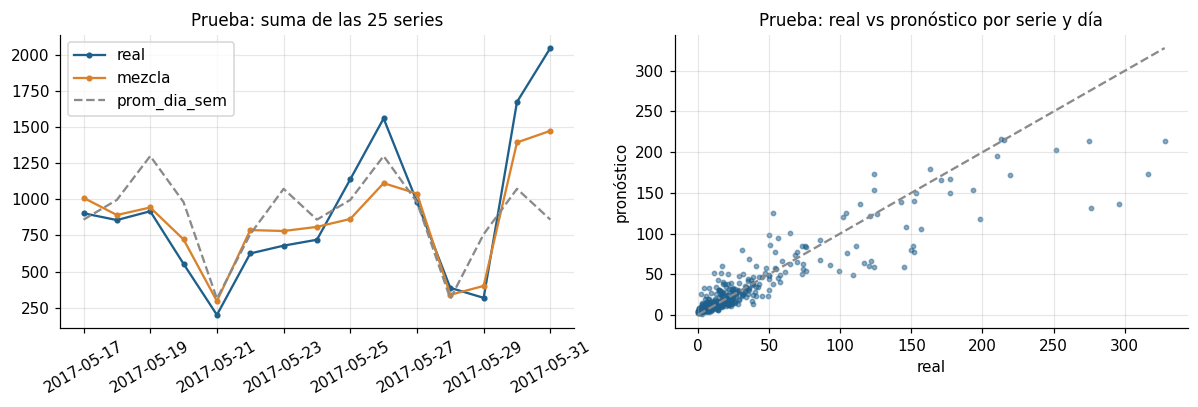

In [23]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
dias = fechas[o:o + H]
axs[0].plot(dias, real.sum(1), color=AZUL, marker='o', ms=3, label='real')
axs[0].plot(dias, pred_folds[o][MEJOR].sum(1), color=NARANJA, marker='o', ms=3, label=MEJOR)
axs[0].plot(dias, pred_folds[o][MEJOR_BASE].sum(1), color=GRIS, ls='--', label=MEJOR_BASE)
axs[0].set_title('Prueba: suma de las 25 series'); axs[0].legend(); axs[0].tick_params(axis='x', rotation=30)
axs[1].scatter(real.ravel(), pred_folds[o][MEJOR].ravel(), s=8, alpha=.5, color=AZUL)
mx = max(real.max(), pred_folds[o][MEJOR].max())
axs[1].plot([0, mx], [0, mx], color=GRIS, ls='--')
axs[1].set_xlabel('real'); axs[1].set_ylabel('pronóstico'); axs[1].set_title('Prueba: real vs pronóstico por serie y día')
fig.tight_layout(); fig.savefig(OUT / 'fig07_prueba.png'); plt.show()
res.to_csv(OUT / 'metricas_validacion.csv', index=False)

### Lectura de los resultados

Los baselines simples sirven de referencia. Repetir el último día o la última semana funciona mal a 15 días (WAPE de 0,78 y 0,68), porque los domingos y festivos se copian al resto de la semana. El mejor baseline es el promedio por día de la semana (WAPE promedio de 0,453, y 0,445 en prueba). Holt-Winters no mejora esa referencia, lo cual no sorprende con solo 17 semanas para estimar nivel y estacionalidad de cada serie.

Al incorporar el calendario el error baja bastante. Poisson con solo día de la semana y festivo queda en 0,412; con efecto de inicio y fin de mes baja a 0,353; el boosting global, que también ve el día del mes, queda en 0,384. Elegí la mezcla de Poisson con calendario y boosting: WAPE promedio de 0,350 en los cuatro cortes y 0,322 en la prueba, contra 0,445 del mejor baseline, una reducción de 28% en prueba y 23% en promedio. El MAE en prueba pasa de 16,1 a 11,6 transacciones por serie y día, el sesgo es de -5% (tiende a subestimar un poco) y el modelo le gana al baseline en 22 de las 25 series.

La diferencia entre los dos mejores es mínima. La mezcla y el Poisson con calendario están casi empatados (0,350 y 0,353 en promedio) y con 4 cortes y 25 series no puedo decir que uno sea mejor. Me quedo con la mezcla por tener un error un poco menor y por promediar dos modelos de naturaleza distinta, que da algo de estabilidad. Además escogí entre nueve modelos mirando los mismos cuatro cortes, así que el error real a futuro probablemente sea algo mayor que el reportado.

Por serie, el error depende del tamaño. Las series grandes (operaciones 0 y 3 en las terminales 1774 y 1910) tienen WAPE de 0,22 a 0,26, mientras que las de la operación 4 y varias de la operación 1 llegan a 0,5 y hasta 0,8 (la peor es la terminal 1774 con operación 4: 0,80 y sesgo de +75%). El error crece con el horizonte, de 0,29 en los primeros cinco días a 0,44 en los últimos cinco. Al sumar las 25 series el WAPE baja a 0,19, porque los errores de cada serie se compensan en parte. Por eso el pronóstico agregado es bastante más confiable que el de una serie individual.

### Respuestas a los puntos pedidos

a) Calidad y cantidad de la información. La base está limpia en lo básico (sin nulos ni duplicados), pero tiene varios problemas que afectan al modelo. Solo hay 121 días de historia, o sea cuatro ciclos mensuales y cinco festivos, y con eso se aprende poco de la estacionalidad mensual y de los festivos. Algunas terminales dejan de reportar o empiezan tarde (1963, 1828, 1515), y ahí no se distingue un apagón de falta de demanda. El primer día es parcial. Además hay una cola de operaciones y combinaciones con tan pocos datos que no se pueden pronosticar por día; me quedé con 25 de las 1.296 combinaciones. Con un año de datos se podría estimar la estacionalidad anual y el efecto de quincenas y festivos con bastante más seguridad.

b) Justificación del modelo y alternativas. Partí de baselines simples (ingenuo, ingenuo estacional, media móvil y promedio por día de la semana) y probé Holt-Winters, regresión de Poisson por serie y boosting global con pérdida de Poisson. Usé modelos de conteos porque la variable es un entero no negativo y hay muchas series pequeñas. Probé la mezcla porque con tan poca historia un modelo por serie es inestable, y uno global comparte información entre series. No usé SARIMA ni redes neuronales: con 121 puntos por serie, estacionalidad semanal y un patrón mensual que se repite solo cuatro veces, no hay datos para estimarlos bien, y además son más difíciles de explicar. Todos los modelos se evaluaron con origen móvil (cuatro ventanas de 15 días, siempre pronosticando hacia adelante) y las mismas métricas, y elegí por WAPE promedio.

c) Validez. En la ventana de prueba (17 al 31 de mayo) el modelo tiene WAPE 0,322, MAE 11,6, RMSE 22,8 y sesgo de -5%, contra 0,445, 16,1, 31,3 y -1% del mejor baseline. Queda por debajo del baseline en los cuatro cortes. Limitaciones: la ventana de prueba contiene un festivo (29 de mayo) y el cierre de mes, y el efecto del día del mes se estimó con cuatro ciclos, así que el pronóstico de los primeros días de junio depende de que ese patrón se repita. Lo más débil es el error en las series pequeñas, donde el modelo apenas supera al baseline.

## E. Pronóstico final: 1 al 15 de junio de 2017

Reentreno el modelo elegido con los 121 días completos y pronostico las 25 series. Entre el 1 y el 15 de junio no hay festivos en Colombia en 2017 (el siguiente es el 19), y así lo toma la variable de festivo. Para dar una idea de la incertidumbre agrego un rango aproximado: al pronóstico le sumo los percentiles 10 y 90 de los errores que el mismo modelo cometió en cada serie en los cuatro cortes de validación.

In [24]:
final = pronosticar(ys, fechas, n)[MEJOR]
# rango empírico con los residuos de la validación
resid = np.vstack([ys[o_:o_ + H] - pred_folds[o_][MEJOR] for o_ in ORIGENES])
lo = np.clip(final + np.percentile(resid, 10, axis=0), 0, None)
hi = np.clip(final + np.percentile(resid, 90, axis=0), 0, None)

dias_f = fechas[n:n + H]
filas = []
for s, (t, op) in enumerate(Y.columns):
    for h, d in enumerate(dias_f):
        filas.append(dict(fecha=d.date(), idTerminal=t, oper=op, prediccion=round(final[h, s], 2),
                          limite_inferior=round(lo[h, s], 2), limite_superior=round(hi[h, s], 2)))
pred = pd.DataFrame(filas)
pred.to_csv(OUT / 'predicciones_15dias.csv', index=False)
print(pred.shape, '| modelo:', MEJOR)
pred.head(8)

(375, 6) | modelo: mezcla


,fecha,idTerminal,oper,prediccion,limite_inferior,limite_superior
0,2017-06-01,1774,0,259.87,192.01,334.82
1,2017-06-02,1774,0,244.75,176.89,319.70
2,2017-06-03,1774,0,189.60,121.74,264.55
3,2017-06-04,1774,0,85.50,17.64,160.44
4,2017-06-05,1774,0,184.27,116.41,259.21
5,2017-06-06,1774,0,174.57,106.71,249.52
6,2017-06-07,1774,0,146.96,79.10,221.91
7,2017-06-08,1774,0,142.80,74.94,217.75


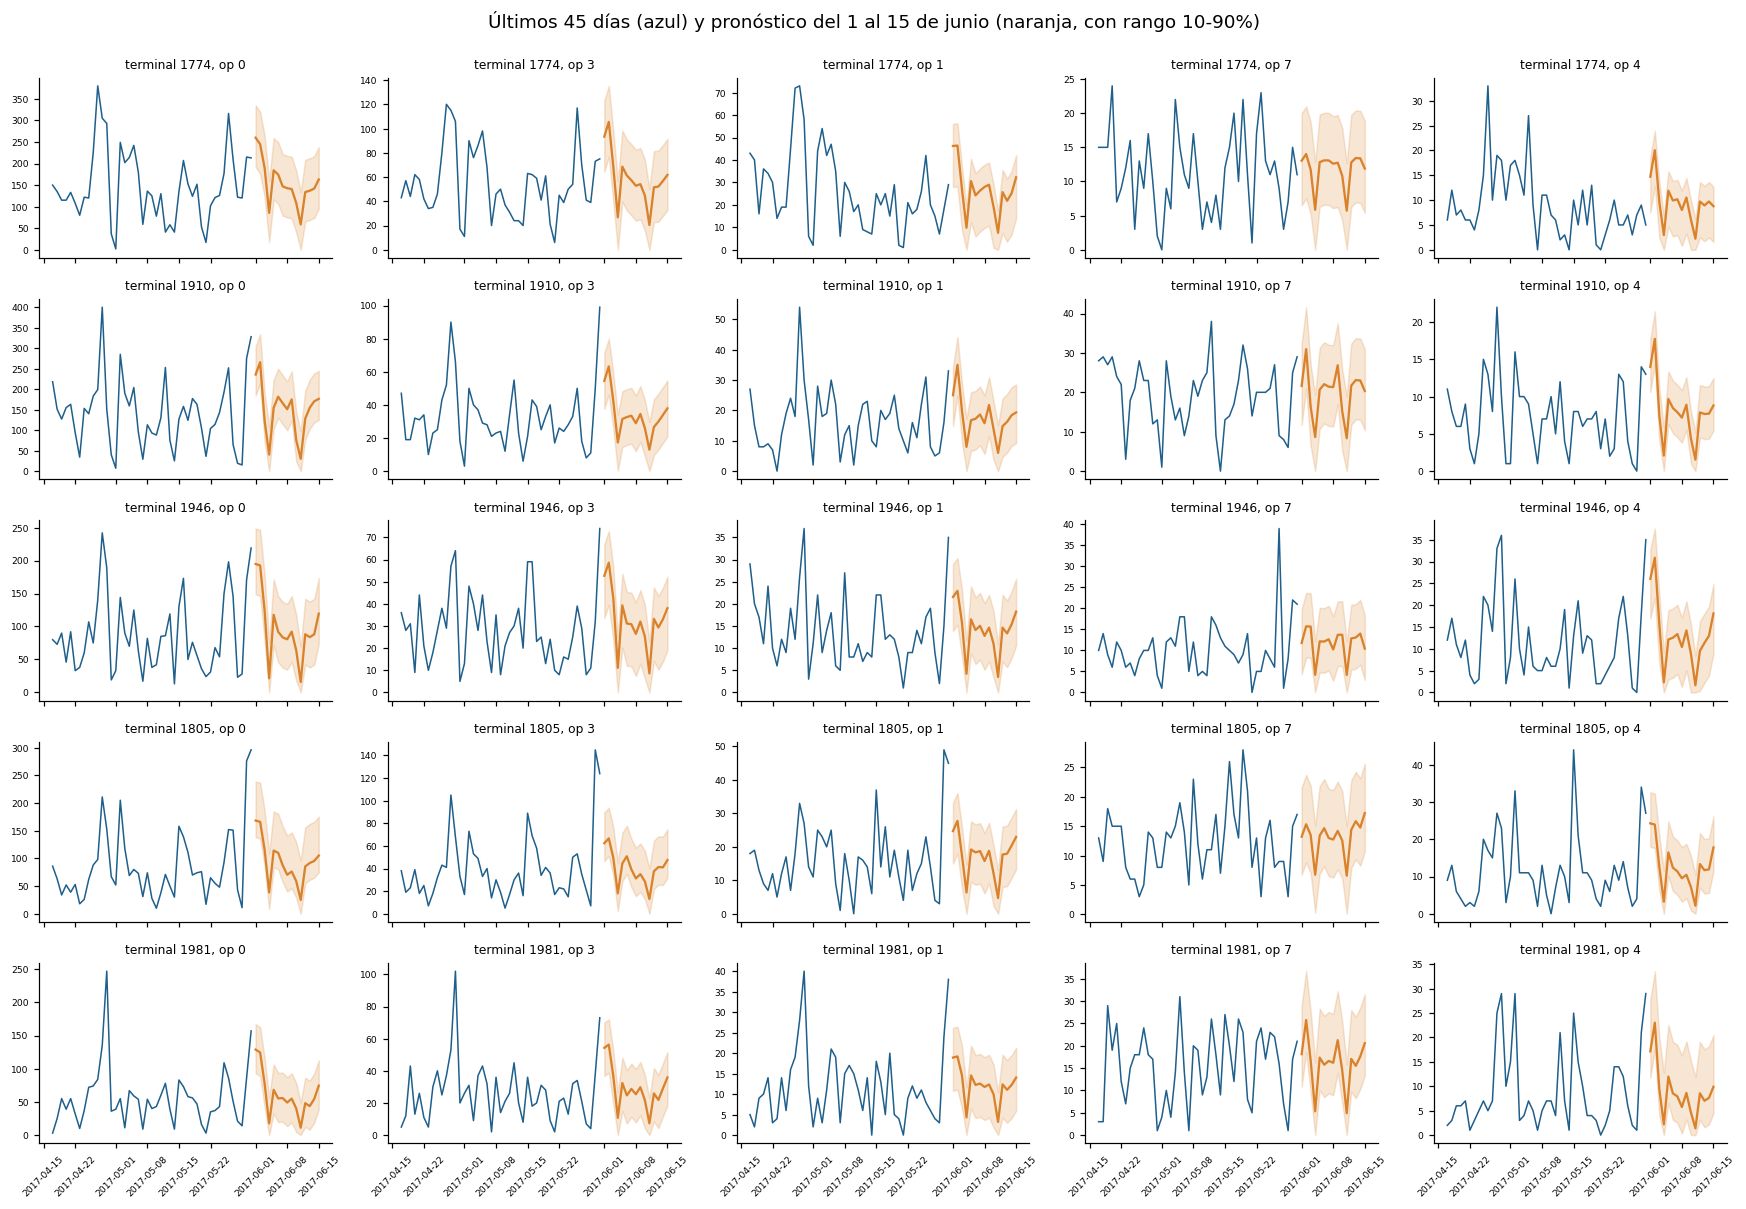

In [25]:
fig, axs = plt.subplots(5, 5, figsize=(16, 11), sharex=True)
for s, (t, op) in enumerate(Y.columns):
    ax = axs[TERM.index(t), OPS.index(op)]
    hist = Y.iloc[-45:, s]
    ax.plot(hist.index, hist.values, color=AZUL, lw=1)
    ax.plot(dias_f, final[:, s], color=NARANJA, lw=1.5)
    ax.fill_between(dias_f, lo[:, s], hi[:, s], color=NARANJA, alpha=.2)
    ax.set_title(f'terminal {t}, op {op}', fontsize=8); ax.tick_params(labelsize=6)
    ax.grid(False)
for ax in axs[-1]:
    ax.tick_params(axis='x', rotation=45)
fig.suptitle('Últimos 45 días (azul) y pronóstico del 1 al 15 de junio (naranja, con rango 10-90%)', y=0.995)
fig.tight_layout(); fig.savefig(OUT / 'fig08_pronostico.png'); plt.show()

In [26]:
# comparación con los 15 días previos y por día de la semana
prev = ys[-15:].sum()
fut = final.sum()
print('suma de las 25 series, últimos 15 días reales:', int(prev), '| pronóstico de los 15 días siguientes:', int(round(fut)))
print(pd.Series(final.sum(1), index=dias_f.strftime('%a %d-%m')).round(0).astype(int).to_string())
print('\npronóstico total por terminal (15 días):')
print(pd.Series(final.sum(0), index=Y.columns).groupby(level=0).sum().round(0).astype(int).to_string())

suma de las 25 series, últimos 15 días reales: 13556 | pronóstico de los 15 días siguientes: 14440
Thu 01-06    1615
Fri 02-06    1713
Sat 03-06    1092
Sun 04-06     364
Mon 05-06    1091
Tue 06-06    1030
Wed 07-06     948
Thu 08-06     857
Fri 09-06     963
Sat 10-06     658
Sun 11-06     267
Mon 12-06     871
Tue 13-06     894
Wed 14-06     968
Thu 15-06    1110

pronóstico total por terminal (15 días):
idTerminal
1774    3907
1805    2665
1910    3423
1946    2540
1981    1905


El pronóstico suma 14.440 transacciones en los 15 días para las 25 series, contra 13.556 de los 15 días anteriores (datos reales del 17 al 31 de mayo, que incluyen un festivo). La forma es la que esperaba: arranque alto el 1 y 2 de junio (cambio de mes), caída el fin de semana del 3 y 4, un valle a mitad de mes y repunte hacia la quincena. Las bandas son anchas, sobre todo en las series pequeñas, y es lo esperable con tan poca historia. La banda muestra el rango en que se movieron los errores en validación; no es un intervalo con cobertura garantizada. Dos supuestos a tener presentes: que no hay festivos hasta el 15 de junio y que el patrón de inicio de mes visto en cuatro ciclos se repite.

In [27]:
# cifras que se usan en el informe
o = ORIGENES[-1]; real = ys[o:o + H]
resumen_json = dict(
    total=len(df), dias=len(todos), terminales=int(df.idTerminal.nunique()), operaciones=int(df.oper.nunique()),
    prom_habil=float(d_ok[d_ok.index.dayofweek < 5].mean()), prom_sab=float(d_ok[d_ok.index.dayofweek == 5].mean()),
    prom_dom=float(d_ok[d_ok.index.dayofweek == 6].mean()),
    pico_dia=str(diario.idxmax().date()), pico=int(diario.max()),
    pct_op0=float(ops.iloc[0] / ops.sum() * 100), pct_top4_ops=float(ops.head(4).sum() / ops.sum() * 100),
    pct_top10_term=float(tt.head(10).sum() / tt.sum() * 100),
    k80_term=k80s['terminales'], n_term=int(len(tt)),
    pct_0_6h=float((df.hora < 6).mean() * 100), pct_8_18h=float(df.hora.between(8, 18).mean() * 100),
    term=TERM, ops=OPS, mejor=MEJOR, mejor_base=MEJOR_BASE,
    wape_modelo_prom=float(prom.WAPE[MEJOR]), wape_base_prom=float(prom.WAPE[MEJOR_BASE]),
    wape_modelo_test=float(prueba.WAPE[MEJOR]), wape_base_test=float(prueba.WAPE[MEJOR_BASE]),
    mae_modelo_test=float(prueba.MAE[MEJOR]), mae_base_test=float(prueba.MAE[MEJOR_BASE]),
    sesgo_test=float(prueba.sesgo[MEJOR]),
    wape_total_test=float(np.abs(pred_folds[o][MEJOR].sum(1) - real.sum(1)).sum() / real.sum()),
    prev15=int(prev), fut15=int(round(fut)),
    fut_dia={d.strftime('%a %d-%m'): float(v) for d, v in zip(dias_f, final.sum(1))},
    fut_terminal={int(k): float(v) for k, v in pd.Series(final.sum(0), index=Y.columns).groupby(level=0).sum().items()})
json.dump(resumen_json, open(OUT / 'resumen.json', 'w'), ensure_ascii=False, indent=1)